# 06 · Banco de pruebas de modelos de ML y calibración del ranker

Se probaron todos los modelos razonables para el tamaño de los datos (137 personas, 8 tipos de experiencia), **con el mismo protocolo**: validación cruzada 5-fold repetida 10 veces, separando personas, e IC 95 % bootstrap de la diferencia contra la popularidad.

* **Tarea A — arranque en frío:** solo con el perfil (estrés, bienestar, síntomas, estresores, edad) ordenar los 8 tipos.
* **Tarea B — completar preferencias:** la persona declara la mitad de lo que eligió y el modelo debe encontrar la otra mitad (filtrado colaborativo).

El cálculo completo está en `src/experimentos_modelos.py` (≈15 min); este notebook lee sus resultados guardados.

In [1]:
import sys, json
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
REPORTS = SRC.parent / 'reports'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab_graficas import aplicar_estilo, guardar, SERIES, TEXTO_2
aplicar_estilo()

In [2]:
r = json.loads((REPORTS / 'experimentos_modelos.json').read_text(encoding='utf-8'))
nombres = {
    'popularidad': 'Popularidad (baseline)', 'logistica_L2_estres': 'Regresión logística L2 · estrés',
    'logistica_L2_perfil': 'Regresión logística L2 · perfil', 'logistica_L1_perfil': 'Regresión logística L1 (lasso) · perfil',
    'naive_bayes_perfil': 'Naive Bayes · perfil', 'random_forest_perfil': 'Random Forest · perfil',
    'gradient_boosting_perfil': 'Gradient Boosting · perfil', 'red_neuronal_mlp_perfil': 'Red neuronal (MLP) · perfil',
    'knn_usuarios_perfil_k15': 'kNN usuarios (CF) · perfil', 'knn_usuarios_estres_k15': 'kNN usuarios (CF) · estrés',
    'random_forest_encogido_50': 'Random Forest encogido a popularidad',
    'coocurrencia_item_item': 'CF ítem-ítem (co-ocurrencia)', 'knn_usuario_usuario': 'CF usuario-usuario (kNN)',
    'logistica_tipos': 'Logística con tipos declarados', 'logistica_tipos_mas_estres': 'Logística con tipos + estrés',
}
def tabla(tarea, m1):
    t = pd.DataFrame(r[tarea]).T
    t.index = [nombres.get(i, i) for i in t.index]
    return t
a = tabla('tarea_a_arranque_en_frio', 'ndcg@3')
print('personas:', r['n_personas'], '| repeticiones:', r['repeticiones'])
a

personas: 137 | repeticiones: 10


,ndcg@3,precision@3,dif_vs_popularidad,ic95,supera_baseline
kNN usuarios (CF) · estrés,0.6501,0.5513,0.0024,"[-0.0157, 0.0207]",False
Popularidad (baseline),0.6477,0.5384,NaN,NaN,NaN
Regresión logística L2 · estrés,0.6391,0.5431,-0.0086,"[-0.0272, 0.0099]",False
Random Forest encogido a popularidad,0.6366,0.5433,-0.0111,"[-0.0252, 0.0023]",False
Random Forest · perfil,0.6291,0.5448,-0.0186,"[-0.0389, 0.0027]",False
kNN usuarios (CF) · perfil,0.6247,0.5353,-0.023,"[-0.0408, -0.007]",False
Regresión logística L1 (lasso) · perfil,0.6067,0.5309,-0.0409,"[-0.0705, -0.0126]",False
Gradient Boosting · perfil,0.5978,0.5182,-0.0499,"[-0.0799, -0.0212]",False
Regresión logística L2 · perfil,0.5932,0.5207,-0.0545,"[-0.0903, -0.021]",False
Naive Bayes · perfil,0.5211,0.4633,-0.1266,"[-0.1699, -0.0845]",False


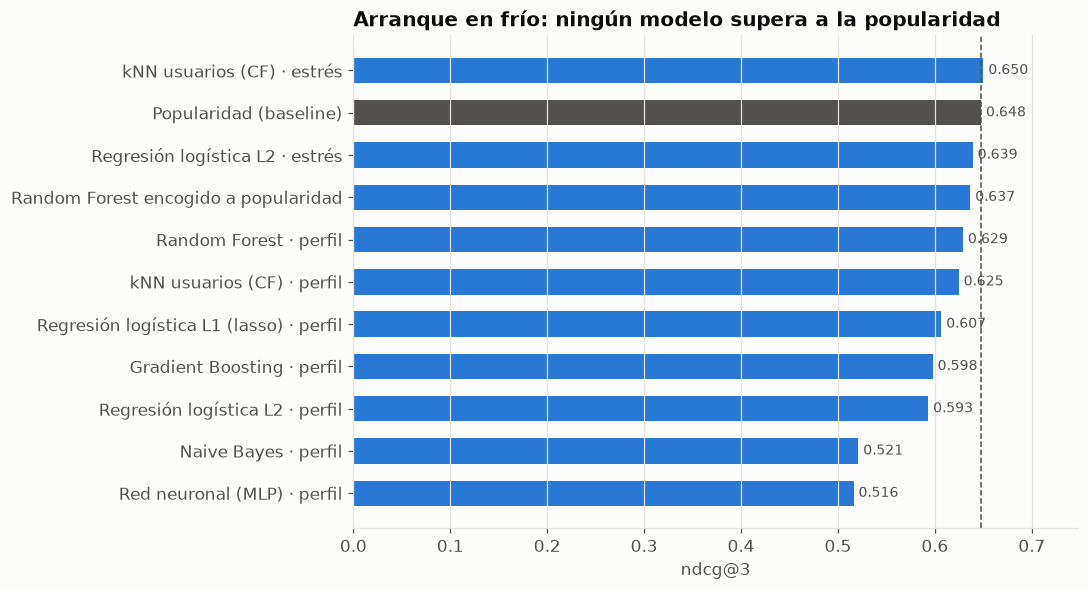

In [3]:
def grafica(t, metrica, titulo, archivo):
    t = t.sort_values(metrica)
    base = t.loc['Popularidad (baseline)', metrica]
    fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(t) + 1.2))
    colores = [TEXTO_2 if i == 'Popularidad (baseline)' else (SERIES[1] if v.get('supera_baseline') is True else SERIES[0]) for i, v in t.iterrows()]
    ax.barh(t.index, t[metrica].astype(float), color=colores, height=0.6)
    ax.axvline(base, color=TEXTO_2, linestyle='--', linewidth=1)
    for i, v in enumerate(t[metrica].astype(float)):
        ax.text(v + 0.005, i, f'{v:.3f}', va='center', color=TEXTO_2, fontsize=9)
    ax.set_xlim(0, max(t[metrica].astype(float)) * 1.15); ax.set_xlabel(metrica); ax.grid(axis='y', visible=False)
    ax.set_title(titulo)
    guardar(fig, archivo)
grafica(a, 'ndcg@3', 'Arranque en frío: ningún modelo supera a la popularidad', '06_modelos_arranque_frio')

,hitrate@2,mrr,dif_vs_popularidad,ic95,supera_baseline
CF ítem-ítem (co-ocurrencia),0.6094,0.6111,0.0187,"[-0.0065, 0.0444]",False
Logística con tipos declarados,0.6055,0.6079,0.0148,"[-0.0335, 0.0613]",False
Logística con tipos + estrés,0.6013,0.6078,0.0106,"[-0.04, 0.0609]",False
Popularidad (baseline),0.5907,0.6119,NaN,NaN,NaN
CF usuario-usuario (kNN),0.5839,0.6069,-0.0068,"[-0.0277, 0.0139]",False


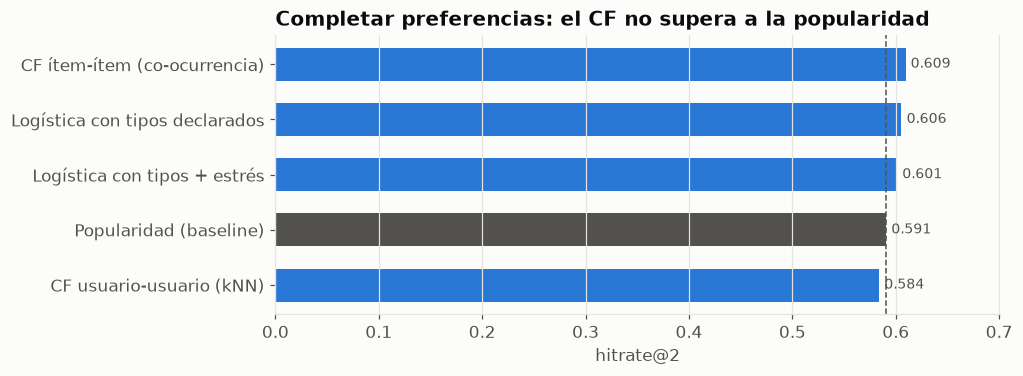

In [4]:
b = tabla('tarea_b_completar_preferencias', 'hitrate@2')
grafica(b, 'hitrate@2', 'Completar preferencias: el CF no supera a la popularidad', '06_modelos_completar')
b

**Lectura.** Con 137 personas:
* Los modelos flexibles (red neuronal, Naive Bayes, boosting, logística con 26 variables) **sobreajustan** y quedan por debajo de la popularidad, con un IC 95 % completamente negativo.
* Los modelos simples basados en estrés (kNN por estrés, logística L2) y el filtrado colaborativo ítem-ítem **empatan** con la popularidad: su IC 95 % incluye el 0.
* Conclusión: los datos sostienen un modelo **popularidad + efecto del estrés con evidencia** (notebook 03). Para aprender más se necesitan más personas; el sistema ya guarda la retroalimentación de uso para la etapa B.

## Calibración de α: cuánto pesa lo que la persona elige en la app

Escenario de la app: cada persona declara la mitad de sus elecciones de P10 (traducidas a modalidades W) y el ranker recomienda 5 lugares del catálogo DENUE.
* **Todas:** acierto contra todo lo que eligió (mide ajuste a la persona).
* **Ocultas:** acierto solo contra lo que no declaró (mide descubrimiento).

In [5]:
d = pd.read_csv(REPORTS / 'escenario_app_alfa.csv')
t = d.groupby(['alfa', 'estres'])[['precision@5_todas', 'ndcg@5_todas', 'precision@5_ocultas']].mean().round(3)
t

precision@5_todas  ndcg@5_todas  precision@5_ocultas
alfa estres                                                      
0.0  False               0.850         0.920                0.504
     True                0.852         0.916                0.506
0.3  False               0.880         0.938                0.476
     True                0.880         0.939                0.473
0.6  False               0.914         0.976                0.385
     True                0.916         0.976                0.374
0.8  False               0.920         0.973                0.356
     True                0.920         0.973                0.356
1.0  False               0.921         0.971                0.323
     True                0.921         0.971                0.323

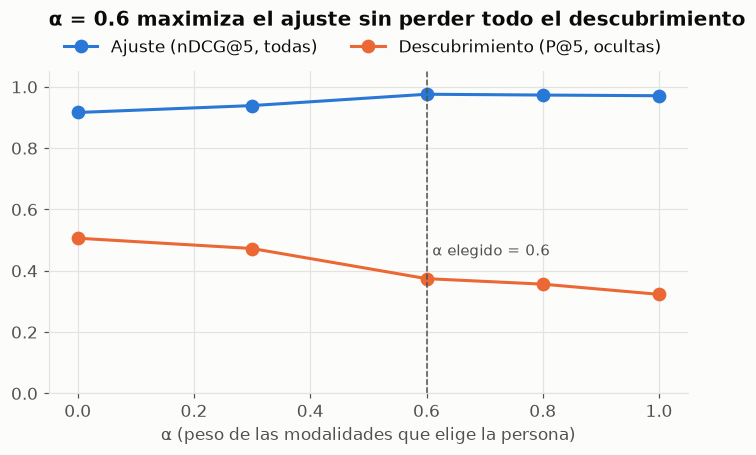

In [6]:
g = d[d['estres']].groupby('alfa')[['ndcg@5_todas', 'precision@5_ocultas']].mean()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(g.index, g['ndcg@5_todas'], marker='o', color=SERIES[0], linewidth=2, markersize=8, label='Ajuste (nDCG@5, todas)')
ax.plot(g.index, g['precision@5_ocultas'], marker='o', color=SERIES[1], linewidth=2, markersize=8, label='Descubrimiento (P@5, ocultas)')
ax.axvline(0.6, color=TEXTO_2, linestyle='--', linewidth=1)
ax.text(0.61, 0.45, 'α elegido = 0.6', color=TEXTO_2, fontsize=10)
ax.set_xlabel('α (peso de las modalidades que elige la persona)'); ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0), ncols=2)
ax.set_title('α = 0.6 maximiza el ajuste sin perder todo el descubrimiento', pad=30)
guardar(fig, '06_calibracion_alfa');

## Inventario de modelos

| Etapa | Modelo | Estado |
|---|---|---|
| Probado y en uso | Popularidad + regresión logística del estrés con selección FDR (`welltur_preferencias_v1`) | ✅ producción local |
| Probado y en uso | Ranker de contenido (similitud coseno W1–W7) + diversidad + cuota MiPyME, α = 0.6 | ✅ producción local |
| Probado, descartado por datos | Logística L1/L2 con perfil, Random Forest, Gradient Boosting, Naive Bayes, MLP, kNN usuario, CF ítem-ítem | ❌ no superan al baseline con n = 137 |
| Pendiente de datos | Etapa B: ranker pareado con retroalimentación real (`train_welltur_mw.py`; requiere ≥ 200 usuarios y ≥ 1000 pares) | ⏳ la app ya registra impresiones y valoraciones |
| Futuro | LambdaMART o CF híbrido (LightFM) con miles de usuarios | 🔜 |
| Descartado | Clasificador de "tipos de estrés" (52.7 % con etiquetas sintéticas) | ❌ sin validez |